# M10-3 | Fallback Report: Which Ops Run on the VPU and Which Fall Back to CPU

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m10_custom_backend/03_fallback_report.ipynb)

The VPU has kernels only for the ops in `VPU_OPS`. `MyVPUQuantizer` does not annotate other ops, so they run in fp32 on the Q/DQ graph; at deployment these ops must be handed to the CPU, and the graph is cut into several pieces as a result.

This notebook writes a minimal partitioner `partition` that reads the Q/DQ graph from `convert_pt2e` and answers the three things you most want to know before deployment:

| Question | Rule |
|---|---|
| Where does each op run? | in `VPU_OPS` and its inputs come from a dequantize or another VPU op → VPU; everything else → CPU |
| How many VPU subgraphs? | VPU ops connected through q → dq (int8 stays on the VPU) or directly count as the same subgraph |
| Where are the boundaries, and how much is moved? | wherever a q/dq has the VPU on one side and the CPU (or the model's input/output) on the other |

- **A.** TinyConvNet: only `adaptive_avg_pool2d` is not on the list.
- **B.** OpZooNet (a model in `common/models.py` that packs in many kinds of ops): more than half of the ops are not on the list, and the graph is shattered.

In [1]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m10_custom_backend")

In [2]:
from dataclasses import dataclass

import graphviz
import torch
from torch.fx import Node

from common.pt2e import quiet
from common.graph_utils import short
from common.models import OpZooNet, TinyConvNet, example_inputs
from common.viz import FONT, table
from vpu_quantizer import VPU_OPS, vpu_ptq

quiet()
_ = torch.manual_seed(0)
QD = torch.ops.quantized_decomposed
Q_T, DQ_T, DQ_C = QD.quantize_per_tensor.default, QD.dequantize_per_tensor.default, QD.dequantize_per_channel.default

## The Partitioner

First a small function that looks through q/dq to find where an activation comes from, then `partition`. Ops of the same subgraph are merged with union-find (`parent` points to the root of the group):

In [3]:
def source(a: Node) -> Node | None:
    """Look through "q -> dq" to find the activation's real source; for weight/bias (get_attr, dequantize_per_channel) return None."""
    if a.op == "get_attr" or (a.op == "call_function" and a.target == DQ_C):
        return None
    if a.op == "call_function" and a.target == DQ_T:
        q = a.args[0]
        assert isinstance(q, Node) and isinstance(q.args[0], Node)
        return q.args[0]
    return a


def partition(gm):
    """Return (ops, device, group): the compute nodes in execution order, the device of each node, and which subgraph each VPU node belongs to."""
    ops = [n for n in gm.graph.nodes if n.op == "call_function" and n.target not in (Q_T, DQ_T, DQ_C)]
    device, parent = {}, {}

    def find(n):
        while parent[n] is not n:
            n = parent[n]
        return n

    for n in ops:
        ins = [a for a in n.all_input_nodes if source(a) is not None]
        # inputs all pass through a dequantize (int8 comes in) or come from another VPU op (a fused relu) -> VPU
        quantized = all(a.target == DQ_T or device.get(a) == "VPU" for a in ins)
        device[n] = "VPU" if n.target in VPU_OPS and quantized else "CPU"
        if device[n] == "VPU":
            parent[n] = n
            for a in ins:
                src = source(a)
                if device.get(src) == "VPU":  # the previous VPU op hands its int8 output straight to this op: same subgraph
                    parent[find(n)] = find(src)
    roots = list(dict.fromkeys(find(n) for n in ops if device[n] == "VPU"))
    group = {n: roots.index(find(n)) for n in ops if device[n] == "VPU"}
    return ops, device, group


def crossings(gm, ops, device):
    """Cross-device boundaries: [(direction, source node, handed to, shape, int8 bytes)]. The model's input and output count as being on the CPU (host) side."""
    where = lambda n: device.get(n, "CPU")  # noqa: E731
    out = []
    for n in ops + [next(n for n in gm.graph.nodes if n.op == "output")]:
        for a in n.all_input_nodes:
            src = source(a)
            if src is not None and where(src) != where(n):
                val = src.meta.get("val")
                shape = tuple(val.shape) if isinstance(val, torch.Tensor) else ()
                out.append((f"{where(src)}→{where(n)}", src, n, shape, int(torch.Size(shape).numel())))
    return out

The partitioned graph: only compute ops are drawn (no q/dq), one box per VPU subgraph, CPU ops outside the boxes, and cross-device edges labeled with int8 bytes. The drawing code serves only this notebook, so it is folded:

In [4]:
#| code-fold: true
#| code-summary: Code that draws the partitioned graph
def draw_partition(gm, title):
    ops, device, group = partition(gm)
    cross = {(c[1], c[2]): c[4] for c in crossings(gm, ops, device)}
    g = graphviz.Digraph(format="svg")
    g.attr(rankdir="TB", bgcolor="white", fontname=FONT, label=title, labelloc="t", fontsize="14", nodesep="0.3", ranksep="0.35")
    g.attr("node", fontname=FONT, fontsize="11", shape="box", style="filled,rounded", margin="0.12,0.05", height="0.3")
    g.attr("edge", fontname=FONT, fontsize="9", color="#495057", arrowsize="0.6")
    io = dict(shape="ellipse", style="filled", fillcolor="#E7F5FF", color="#1C7ED6")
    g.node("x", "x", **io)
    g.node("output", "output", **io)
    for k in sorted(set(group.values())):
        c = graphviz.Digraph(name=f"cluster_{k}")  # graphviz draws a subgraph whose name starts with cluster_ as a box
        c.attr(label=f"VPU subgraph #{k}", style="rounded", color="#2B8A3E", fontcolor="#2B8A3E", fontsize="11")
        for n in ops:
            if group.get(n) == k:
                c.node(n.name, short(n.target), fillcolor="#EBFBEE", color="#2B8A3E")
        g.subgraph(c)
    for n in ops:
        if device[n] == "CPU":
            g.node(n.name, f"{short(n.target)}\n(CPU, fp32)", fillcolor="#FFE3E3", color="#C92A2A")
    out_node = next(n for n in gm.graph.nodes if n.op == "output")
    for n in ops + [out_node]:
        for a in n.all_input_nodes:
            src = source(a)
            if src is None:
                continue
            dst = "output" if n is out_node else n.name
            if (src, n) in cross:
                g.edge(src.name if src.op != "placeholder" else "x", dst, label=f"{cross[(src, n)]} B",
                       color="#C92A2A", fontcolor="#C92A2A", style="dashed")
            else:
                g.edge(src.name, dst)
    return g

## A. TinyConvNet

The Q/DQ graph comes from `vpu_ptq` (M10-2): `torch.export.export` (batch 1, static shape) → `prepare_pt2e(…, MyVPUQuantizer())` → calibrate → `convert_pt2e`.

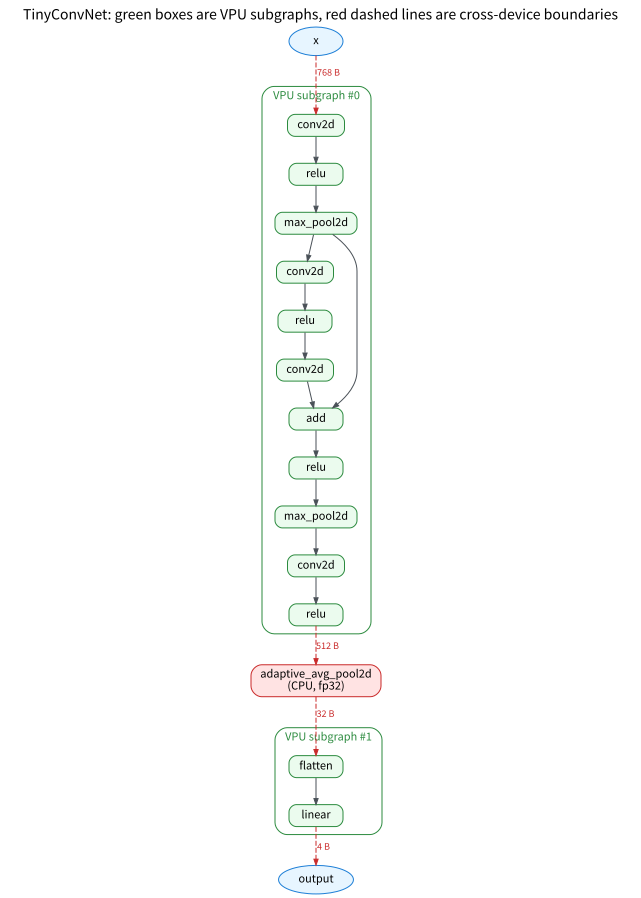

In [5]:
x = example_inputs(1)
tiny = vpu_ptq(TinyConvNet().eval(), x)
draw_partition(tiny, "TinyConvNet: green boxes are VPU subgraphs, red dashed lines are cross-device boundaries")

In [6]:
@dataclass
class Summary:
    vpu: int          # number of VPU ops
    cpu: int          # number of CPU ops
    sizes: list[int]  # number of ops in each VPU subgraph
    n_cross: int      # number of boundaries
    bytes: int        # int8 bytes moved across devices per inference


def boundary_table(gm):
    ops, device, group = partition(gm)
    cross = crossings(gm, ops, device)
    rows = [[d, s.name, n.name if n.op != "output" else "output", str(shape), b] for d, s, n, shape, b in cross]
    sizes = [sum(g == k for g in group.values()) for k in range(len(set(group.values())))]
    n_vpu = sum(d == "VPU" for d in device.values())
    summary = Summary(vpu=n_vpu, cpu=len(ops) - n_vpu, sizes=sizes, n_cross=len(cross), bytes=sum(c[4] for c in cross))
    return rows, summary


rows, s = boundary_table(tiny)
print(f"{s.vpu} VPU ops, {s.cpu} CPU ops; {len(s.sizes)} VPU subgraphs (with {s.sizes} ops each); "
      f"{s.n_cross} boundaries, {s.bytes} bytes moved per inference (counted as int8)")
table(rows, ["Direction", "tensor (node producing it)", "Handed to", "shape", "int8 bytes"])

13 VPU ops, 1 CPU ops; 2 VPU subgraphs (with [11, 2] ops each); 4 boundaries, 1316 bytes moved per inference (counted as int8)


Direction,tensor (node producing it),Handed to,shape,int8 bytes
CPU→VPU,x,conv2d,"(1, 3, 16, 16)",768
VPU→CPU,relu_3,adaptive_avg_pool2d,"(1, 32, 4, 4)",512
CPU→VPU,adaptive_avg_pool2d,flatten,"(1, 32, 1, 1)",32
VPU→CPU,linear,output,"(1, 4)",4


In [7]:
assert s.cpu == 1 and len(s.sizes) == 2 and s.n_cross == 4

`adaptive_avg_pool2d` is not in `VPU_OPS`, and `MyVPUQuantizer` does not annotate it (M10-1 D). On the Q/DQ graph it runs in fp32 sandwiched between a dq and a q, `partition` assigns it to the CPU, and the VPU ops before and after it end up in two subgraphs.

The q/dq at the boundaries are all left by the quantizer's annotations: the dq in front of it is the output annotation of `relu_3` (VPU→CPU), and the q behind it is the annotation on the input edge of `flatten` (CPU→VPU). Each boundary is one int8 ↔ fp32 conversion plus one transfer between devices; the model's input and output count as one each.

## B. OpZooNet: More Than Half of the Ops Are Not on the List

sigmoid, leaky_relu, mul, avg_pool2d, mean, matmul and softmax are all not in `VPU_OPS`:

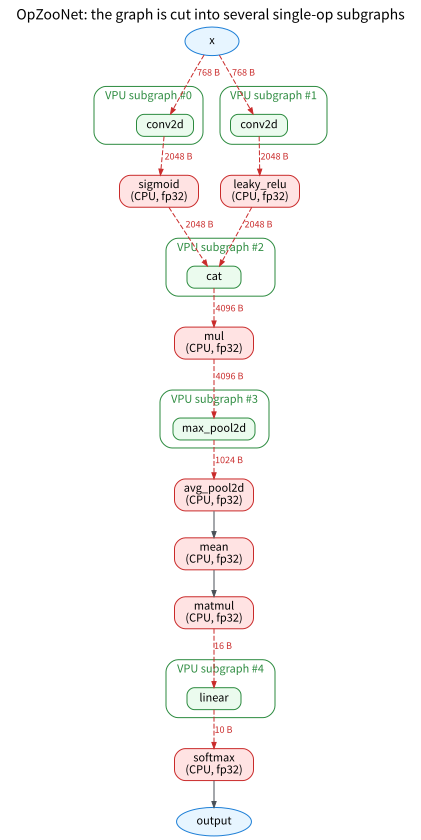

In [8]:
zoo = vpu_ptq(OpZooNet().eval(), x)
draw_partition(zoo, "OpZooNet: the graph is cut into several single-op subgraphs")

In [9]:
rows, s = boundary_table(zoo)
lone = sum(k == 1 for k in s.sizes)
print(f"{s.vpu} VPU ops, {s.cpu} CPU ops; {len(s.sizes)} VPU subgraphs, {lone} of which contain just 1 op; "
      f"{s.n_cross} boundaries, {s.bytes} bytes moved per inference (counted as int8)")
assert s.cpu > s.vpu and lone == len(s.sizes)

5 VPU ops, 7 CPU ops; 5 VPU subgraphs, 5 of which contain just 1 op; 11 boundaries, 18970 bytes moved per inference (counted as int8)


Every VPU subgraph has just 1 op. For example, `max_pool2d` has `mul` before it and `avg_pool2d` after it, both on the CPU, so it enters and leaves the VPU once each just to do one pooling.

For such single-op subgraphs, the cost of the transfer and conversion may exceed just computing on the CPU (an inference; this project has no real-device measurement); the partitioner could add a rule "if a subgraph is too small, keep it on the CPU".

## Summary

- The quantizer and the partitioner read the same `VPU_OPS`: an op the quantizer does not annotate is an op the partitioner falls back to CPU. With both sides consistent, the CPU segment gets fp32 and the VPU segment gets int8.
- This is the same thing as M08-3 (XnnpackPartitioner does not take cumsum) and the M09 overview (ORT's QDQ fusion list): how large a fraction of the model runs on the accelerator depends on the op list, not only on what the quantizer annotated.
- Look at this partitioned graph before deployment: the number of subgraphs, the number of boundaries and the amount of data moved can all be adjusted at the model-architecture stage (for example, replace sigmoid with a relu that is on the list).